## Multiple Linear regression
## single feature

```y = mx + c ```
## multiple features

```price = B1(size) + B2(bedrooms) + B3(age) + B0 ```
example:
price = 200(size) + 50000(bedrooms) 

In [13]:
import numpy as np
import pandas as pd

#create data with multiple features
np.random.seed(42)
n = 200

#generate features, size, bedrooms, age, bathrooms.
size = np.random.randint(800, 3500, n)
bedrooms = np.random.randint(1, 6, n)
age = np.random.randint(0, 50, n)
bathrooms = np.random.randint(1, 4, n)

# generate price based on features with some noise
price = (
        200 * size + 
        50000 * bedrooms + 
        10000 * bathrooms - 
        3000 * age + 
        np.random.normal(0, 50000, n) 
)        


# create a DataFrame
df = pd.DataFrame({
    'size': size,
    'bedrooms': bedrooms,
    'age': age,
    'bathrooms': bathrooms,
    'price': price
})




In [14]:
print(df.head())

   size  bedrooms  age  bathrooms          price
0  1660         4   15          1  496264.087068
1  2094         3   38          2  514620.271485
2  1930         3    4          3  539930.744672
3  1895         1   21          3  312765.340190
4  2438         5   28          2  673290.043016


In [15]:
print(df.describe())

              size    bedrooms         age   bathrooms          price
count   200.000000  200.000000  200.000000  200.000000     200.000000
mean   2225.030000    2.900000   24.840000    1.910000  533751.341900
std     728.920175    1.403513   14.067118    0.815614  166145.172374
min     801.000000    1.000000    0.000000    1.000000   81489.834066
25%    1644.250000    2.000000   12.000000    1.000000  423852.431985
50%    2278.500000    3.000000   25.000000    2.000000  533298.514373
75%    2838.750000    4.000000   36.000000    3.000000  656964.731590
max    3495.000000    5.000000   49.000000    3.000000  948954.630431


In [17]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   size       200 non-null    int32  
 1   bedrooms   200 non-null    int32  
 2   age        200 non-null    int32  
 3   bathrooms  200 non-null    int32  
 4   price      200 non-null    float64
dtypes: float64(1), int32(4)
memory usage: 4.8 KB
None


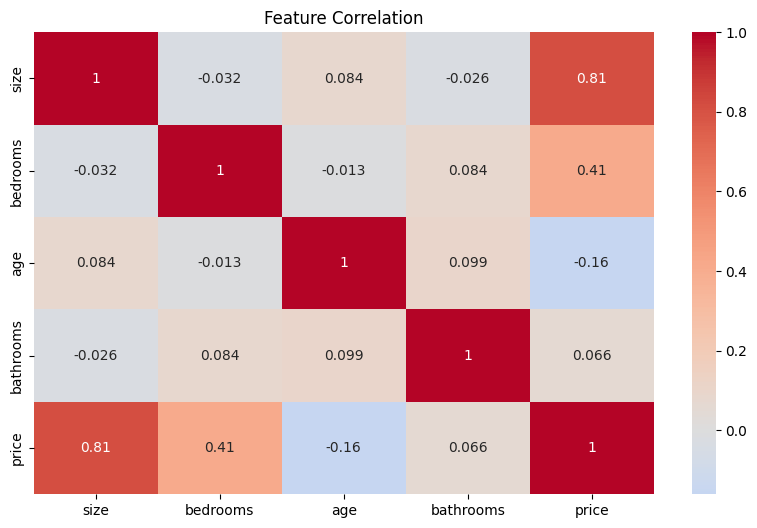

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# correlation matrix
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', center = 0)
plt.title('Feature Correlation')
plt.show()

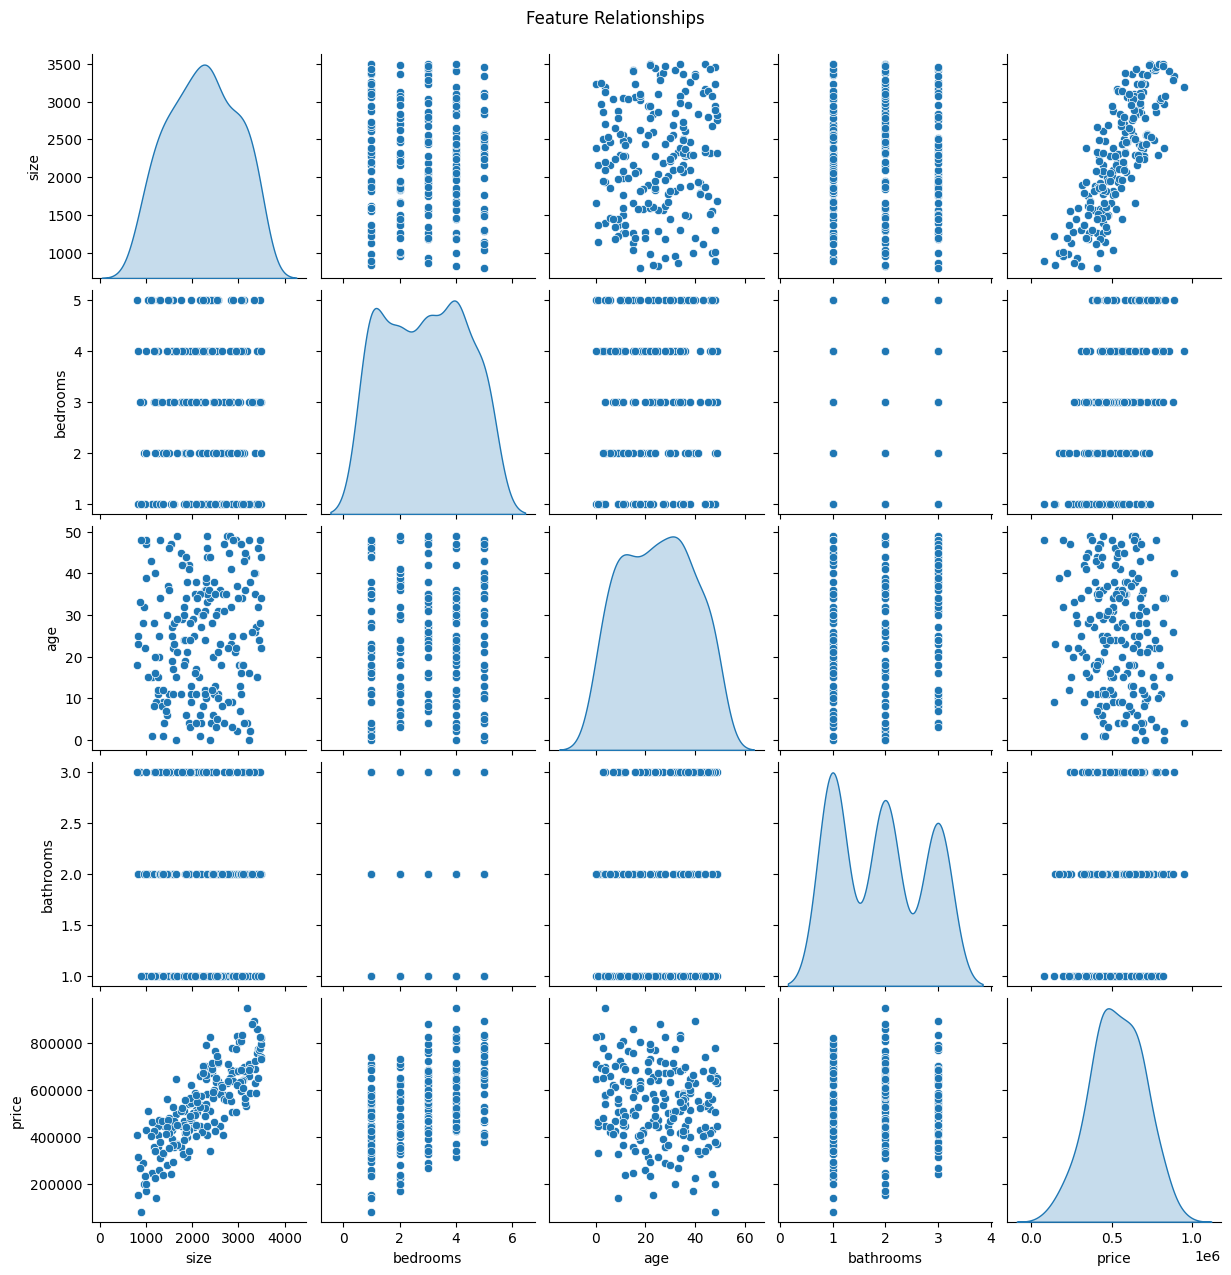

In [20]:
sns.pairplot(df, diag_kind='kde')
plt.suptitle('Feature Relationships', y=1.02)
plt.show()

In [21]:
# prepare data for modeling
from sklearn.model_selection import train_test_split
X = df[['size', 'bedrooms', 'age', 'bathrooms']]
y = df['price']

# split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train a linear regression model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [22]:
# Evaluate the model
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

y_pred = model.predict(X_test)


In [28]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
root_mean_squared_error = rmse
r2 = r2_score(y_test, y_pred)

print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R²: {r2:.2f}')



MSE: 4137471239.70
RMSE: 64323.18
R²: 0.78


# Feature Importance
- Standardized coeficient analysis -> Used to compare feature importance in linear models
## What happens?
We scale our data to a mean of 0 and a standard deviation of 1 so as to ensure a unit
change in one feature (eg age) is mathematically comparable to a unit change in another
(eg salary).

## Why this works?
-Eliminated units ie starndardizes
-Provides true rank -> The features at the top of abs-coefficient list are the strongest
drivers of our model's predictions

## Potential issues to watch for
1.Data Leakage risk
Best practice: Only fit the std scaler on your training data to prevent information leaking to the model.
2. Multi-collinearilty 
If two features are highly correlated, their coefficients might interfere with each other. 
FIX: Check VIF or use Ridge/Lasso regression to stabilize them
3. Standardizing binary (dummy) variables
standardizing 

In [43]:
# Coefficient magnitude
# Starndardize features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # create scaler object
X_train_scaled = scaler.fit_transform(X_train) # fit scaler to training data and transform it
X_test_scaled = scaler.transform(X_test) # transform test data using the same scaler (do not fit again to avoid data leakage)

# retrain model with scaled features
model_scaled = LinearRegression()  # create new model instance
model_scaled.fit(X_train_scaled, y_train)   # fit model to scaled training data


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
# compare coefficients
import pandas as pd
importance =  pd.DataFrame({
    'Feature': X.columns, 
    'Coefficient': model_scaled.coef_, # use scaled coefficients for comparison 
    'Abs_Coefficient': np.abs(model_scaled.coef_) # remove negative sign for comparison
}).sort_values('Abs_Coefficient', ascending=False)  # sort by absolute coefficient for importance ranking 

print(importance) 

     Feature    Coefficient  Abs_Coefficient
0       size  146039.606255    146039.606255
1   bedrooms   77110.480302     77110.480302
2        age  -37311.336233     37311.336233
3  bathrooms   11020.079885     11020.079885


# Regularization - Ridge and Lasso
# The overfitting problem.
This occurs when the model learns the training data too well
i.e
- Memorizes noise and outliers
- Falls on new data.

## Identifying an overfitting problem
When the training r2 is way greater than the test r2.
- Healthy gap -> <5% i.e a difference of 0.01 to 0.05
- warning zone -> 5% to 10% the model is starting to memorize data
- overfitting zone -> >10%, a gap larger than 0.10 usually confirms the overfitting

## Quick fixes for overfitting
- Reducing the number of features/ dropping columns
- Regularization ie lasso (L1) or ridge (L2)
- Adding more data
- Cross validation ie using k-fold cross validation
- Pruning


In [46]:
# checking for the training r2 score to see if there is overfitting
train_r2 = model.score(X_train, y_train)
print(f'Training r2 score: {train_r2} vs the testing r2 score: {r2}')
print(f'Difference: {train_r2 - r2}')

Training r2 score: 0.9240235922170533 vs the testing r2 score: 0.7842704212857896
Difference: 0.13975317093126371


# Regularization
## Example:
Training r2 score: 0.99
Test r2 score: 0.40
What happens: Penalize complex models (large coefficients).
### cost function
Original: MSE = E(actual - predicted) ^ 2

# with regularization
    = MSE + lambda * (penalty on coefficients)
eg ridge cost function.
    = MSE + lambda * E(coefficients ^ 2)

lambda controls regularization strength:
lambda = 0, no regularization (regular linear regression)
small lambda = 0.01 to 1.0, light regularization
moderate lambda = 1.0 to 100
large lambda = 1000+ strong regularization

# Ridge regression
## when to use?
1. many features with small/medium effects
2. All features seem relevant
3. Correlated features

In [50]:
from sklearn.linear_model import Ridge
# create Ridge regression model with regularization strength alpha
Ridge = Ridge(alpha=1.0)  

# fit Ridge model to scaled training data
Ridge.fit(X_train, y_train) 


,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [51]:
# Evaluate Ridge model
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
y_pred_ridge = Ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print(f'Ridge MSE: {mse_ridge:.2f}')
print(f'Ridge R²: {r2_ridge:.2f}')

Ridge MSE: 4126930418.04
Ridge R²: 0.78


# Lasso regression
cost function:
   cost = MSE + Lambda * E|coefficeints|

## Effects of lasso
- Can shrink the coefficients to exactly 0
- Performs automatic feature selection

## When to use?
- Many features and some are irrelevant
- Want automatic feature selection
- Need interpretable model (fewer features).


In [53]:
# lasso regression
from sklearn.linear_model import Lasso  

# create Lasso regression model with regularization strength alpha
lasso = Lasso(alpha=1.0)

# Train Lasso model
lasso.fit(X_train, y_train)


,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [55]:
# Evaluate the Lasso model
from sklearn.metrics import mean_squared_error, r2_score
y_pred_lasso = lasso.predict(X_test)
r2_lasso = r2_score(y_test, y_pred_lasso)
print(f'The R²: {r2_lasso:.2f}')

The R²: 0.78


In [56]:
lasso.coef_

array([  193.95180301, 54490.86296085, -2706.91144174, 13618.6284196 ])